# Task 15, Notebook 14: Group gaps, bands, final selection, outputs and limits

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 15: Recommend fair pay bands  
**Objective:** Test the model for gaps by gender and career gap, output a band, decide what to ship and write the limits down.  
**Workflow stages covered in this notebook:** 32, 33, 34, 35, 36, 37, 38 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3_working | seed: 42


In [2]:
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr.phase3.salary import model as S, run as SR
from cortexhr.phase3.explanations.risk_report import load_helpers
H = load_helpers()
sal = read_csv('salary_training'); df = S.load_salary(); dd = read_csv('data_dictionary')
print('salary rows:', sal.shape, '| engineered:', df.shape)

salary rows: (2934, 17) | engineered: (2934, 20)


In [3]:
o = SR.run_task15(write=True); print('final model:', o['final_model'], '| restricted attributes available:', o['vault'])

final model: Ridge regression (job-related features) | restricted attributes available: True


## Stage 32: Fairness and Bias Evaluation

*What this stage is for:* Gaps between groups, measured with the protected attributes only after the fact.

Group gaps. Gender and age come from the restricted `unlock_CX-15` file and are **never inputs**; they define groups after the fact. Every row has an out-of-sample prediction (out-of-fold for training rows, train-fit for test rows). The supplied `group_gap()` gives best-minus-worst group mean for each measure. 'Pay ratio' = pay divided by (band mid-point x market index), so roles are comparable.

In [4]:
if not o['vault']: print('restricted file not present: fairness measurement skipped')
else:
    print('HISTORY AND PREDICTIONS BY GENDER (mean pay ratio):'); print(o['gender_means'].round(4).to_string()); print(); print('group_gap() by gender:'); print(o['gender_gaps'].round(4).to_string())

HISTORY AND PREDICTIONS BY GENDER (mean pay ratio):
        actual offer / band mid-point (history)  model A predicted ratio  model B predicted ratio (chosen)  model A actual/predicted  model B actual/predicted
gender                                                                                                                                                        
Female                                   0.9841                   0.9864                            0.9885                    0.9979                    0.9957
Male                                     0.9979                   0.9907                            0.9891                    1.0075                    1.0092
Other                                    0.9981                   0.9879                            0.9866                    1.0104                    1.0117

group_gap() by gender:
                                   measure  group_gap  mean[Female]  mean[Male]  mean[Other]
0  actual offer / band mid-point (hi

In [5]:
if o['vault']:
    print('Female minus Male, mean pay ratio, with 95% bootstrap interval:')
    for k, v in o['gender_boot'].items(): print('  %-14s %+.4f  [%+.4f, %+.4f]' % (k, v['difference'], v['ci_low'], v['ci_high']))
    print(); print('career gap by gender:'); print(o['gender_vs_gap'].round(3).to_string())

Female minus Male, mean pay ratio, with 95% bootstrap interval:
  ratio_actual   -0.0138  [-0.0198, -0.0080]
  ratio_pred_A   -0.0043  [-0.0060, -0.0026]
  ratio_pred_B   -0.0005  [-0.0022, +0.0011]

career gap by gender:
         mean  median  share_with_gap
gender                               
Female  3.354     0.0           0.241
Male    0.739     0.0           0.050
Other   0.800     0.0           0.117


In [6]:
if o['vault']:
    print('BY CAREER GAP:'); print(o['gap_bin_means'].round(4).to_string()); print(); print(o['gap_bin_gaps'].round(4).to_string())
    print(); print('BY AGE BAND (group_gap):'); print(o['age_gaps'].round(4).to_string())

BY CAREER GAP:
                actual offer / band mid-point (history)  model A predicted ratio  model B predicted ratio (chosen)  model A actual/predicted  model B actual/predicted
gap_bin                                                                                                                                                               
none                                             0.9953                   0.9915                            0.9889                    1.0040                    1.0067
1-6 months                                       0.9826                   0.9866                            0.9903                    0.9963                    0.9927
7-12 months                                      0.9737                   0.9747                            0.9871                    0.9993                    0.9868
13-24 months                                     0.9584                   0.9583                            0.9851                    1.0003          

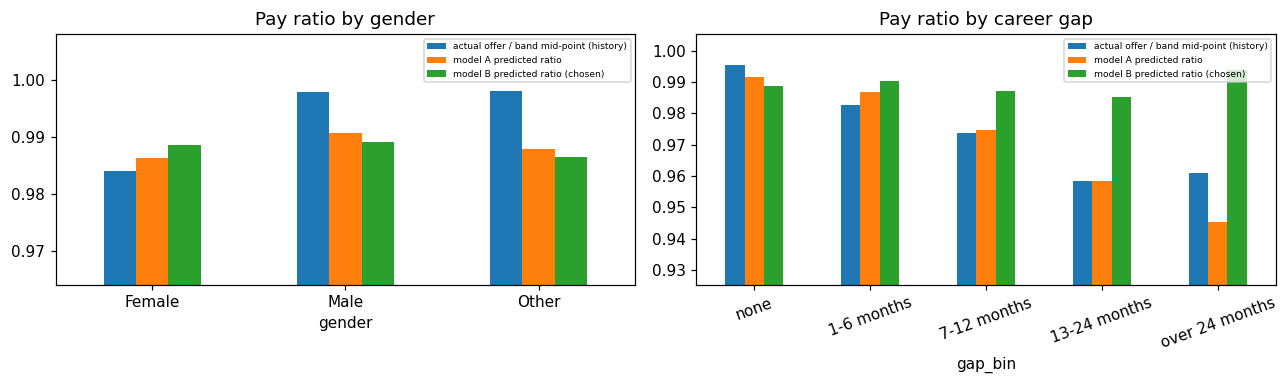

In [7]:
if o['vault']:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6)); gm = o['gender_means'][['actual offer / band mid-point (history)', 'model A predicted ratio', 'model B predicted ratio (chosen)']]; gm.plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(gm.min().min() - .02, gm.max().max() + .01); ax[0].set_title('Pay ratio by gender'); ax[0].legend(fontsize=6)
    cm = o['gap_bin_means'][['actual offer / band mid-point (history)', 'model A predicted ratio', 'model B predicted ratio (chosen)']]; cm.plot.bar(ax=ax[1], rot=20); ax[1].set_ylim(cm.min().min() - .02, cm.max().max() + .01); ax[1].set_title('Pay ratio by career gap'); ax[1].legend(fontsize=6); plt.tight_layout(); plt.savefig(P.FIGURES / 'task15_group_gaps.png', dpi=130, bbox_inches='tight')

In [8]:
if o['vault']:
    gm, cm = o['gender_means'], o['gap_bin_means']; ga = o['gender_gaps'].set_index('measure').group_gap; ca = o['gap_bin_gaps'].set_index('measure').group_gap
    hist_g, a_g, b_g = ga['actual offer / band mid-point (history)'], ga['model A predicted ratio'], ga['model B predicted ratio (chosen)']; hist_c, a_c, b_c = ca['actual offer / band mid-point (history)'], ca['model A predicted ratio'], ca['model B predicted ratio (chosen)']
    print('WHAT THE GAPS MEAN')
    print('- History: by gender the best-minus-worst mean pay ratio is %.4f; by career gap %.4f (offers fall as the gap grows).' % (hist_g, hist_c))
    print('- Model A (career gap allowed as an input) repeats this: gender gap %.4f, career-gap gap %.4f.' % (a_g, a_c))
    print('- Model B (chosen, job-related inputs only): gender gap %.4f, career-gap gap %.4f.' % (b_g, b_c))
    ra = o['gap_bin_means']['model B actual/predicted']; rg_ = o['gender_means']['model B actual/predicted']
    print('- Women hold longer career gaps on average (%.1f vs %.1f months for men), so a career-gap input carries the gender difference into the recommendation even though gender is never an input: a proxy.' % (o['gender_vs_gap'].loc['Female', 'mean'], o['gender_vs_gap'].loc['Male', 'mean']))
    print('- What history still does: actual offers divided by the chosen-model recommendation average %.4f for people with no career gap and %.4f for over 24 months, and %.4f for women vs %.4f for men. People with long gaps (and women) were offered less than the job-related recommendation, so the chosen model does NOT copy that shortfall.' % (ra['none'], ra['over 24 months'], rg_['Female'], rg_['Male']))
    print('- Remaining gender gap in the chosen-model recommendations: %+.4f (95%% interval %+.4f to %+.4f): %s.' % (o['gender_boot']['ratio_pred_B']['difference'], o['gender_boot']['ratio_pred_B']['ci_low'], o['gender_boot']['ratio_pred_B']['ci_high'], 'indistinguishable from zero' if o['gender_boot']['ratio_pred_B']['ci_low'] <= 0 <= o['gender_boot']['ratio_pred_B']['ci_high'] else 'still different from zero'))
    print('WHAT WAS CHANGED: career_gap_months was removed as an input; band recommendations are driven by role, level, band, market, experience, skills, education and location only.')

WHAT THE GAPS MEAN
- History: by gender the best-minus-worst mean pay ratio is 0.0140; by career gap 0.0368 (offers fall as the gap grows).
- Model A (career gap allowed as an input) repeats this: gender gap 0.0043, career-gap gap 0.0462.
- Model B (chosen, job-related inputs only): gender gap 0.0025, career-gap gap 0.0085.
- Women hold longer career gaps on average (3.4 vs 0.7 months for men), so a career-gap input carries the gender difference into the recommendation even though gender is never an input: a proxy.
- What history still does: actual offers divided by the chosen-model recommendation average 1.0067 for people with no career gap and 0.9676 for over 24 months, and 0.9957 for women vs 1.0092 for men. People with long gaps (and women) were offered less than the job-related recommendation, so the chosen model does NOT copy that shortfall.
- Remaining gender gap in the chosen-model recommendations: -0.0005 (95% interval -0.0022 to +0.0011): indistinguishable from zero.
WHAT WAS

**Think for yourself: if women in the data were paid less in the past, should the model copy that?** No. A model trained on past offers learns whatever pattern is in them, including a pattern caused by a career gap penalty. What I did: (1) never use gender or age; (2) exclude career gap, which is not a job requirement and acts as a proxy for gender; (3) measure what is left with the supplied helper and a bootstrap interval; (4) present a *range*, so the manager decides inside it; (5) say plainly that the training target itself may contain past bias, so a model that matches history perfectly is not the goal. What I would add before real use: re-base the target (for example use only recent offers after a pay review, or audit and correct historical offers), review any remaining gap with HR and legal, and monitor offers against the band by gender every quarter.

## Stage 33: Model Calibration or Prediction Reliability

*What this stage is for:* Are the numbers trustworthy as numbers?

Reliability of the range. The band is the model's mid-point times the 10th and 90th percentile of its out-of-fold error, so it should contain about 80% of actual offers. Check on the untouched test set and by group.

In [9]:
print('test coverage of the low..high band: %.3f (target %.2f)' % (o['band_coverage'], CFG['salary']['success_criteria']['band_target_coverage']))
bt = o['bands_test']; print(bt.groupby(pd.cut(o['test'].job_level.to_numpy(), [0, 2, 4, 8]), observed=True).inside_band.agg(['mean', 'size']).round(3).to_string())
if o['vault']:
    t = o['full'][o['full']._part == 'test'].merge(bt[['hire_id', 'inside_band']], on='hire_id'); print(t.groupby('gender').inside_band.agg(['mean', 'size']).round(3).to_string())

test coverage of the low..high band: 0.802 (target 0.80)
         mean  size
(0, 2]  0.777   349
(2, 4]  0.850   213
(4, 8]  0.760    25
         mean  size
gender             
Female  0.789   242
Male    0.813   337
Other   0.750     8


## Stage 34: Model Comparison and Final Selection

*What this stage is for:* Choose on evidence, not on the highest score alone.

Final selection: accuracy lost by removing the career-gap input, against the fairness gain.

In [10]:
tm = o['test_metrics']; fm = o['final_model']; with_gap = 'Gradient boosting + career_gap_months' if fm.startswith('Gradient') else 'Ridge regression + career_gap_months'
cmp_ = tm.loc[[fm, with_gap]].round(3); cmp_

                                         MAE_rupees  RMSE_rupees     R2  median_abs_pct_error  MAE_log
Ridge regression (job-related features)   53924.807    84330.025  0.983                 5.397    0.065
Ridge regression + career_gap_months      53160.626    83054.131  0.984                 5.451    0.064

In [11]:
d = tm.loc[with_gap, 'MAE_rupees'] - tm.loc[fm, 'MAE_rupees']; print('MAE with career gap minus MAE without: Rs %+.0f (%.2f%% of MAE) -> removing the career-gap input costs %s accuracy.' % (d, abs(d) / tm.loc[fm, 'MAE_rupees'] * 100, 'no' if d >= 0 else 'a little'))
print('Final model:', fm, '| version', SR.MODEL_VERSION)

MAE with career gap minus MAE without: Rs -764 (1.42% of MAE) -> removing the career-gap input costs a little accuracy.
Final model: Ridge regression (job-related features) | version salary-band-v1


## Stage 35: Final Prediction Generation

*What this stage is for:* Produce the deliverable.

A band (low, mid, high) for every hire in the test set, and an example for a new role.

In [12]:
bt = o['bands_test']; save_table(bt, P.task_dir(15) / 'band_recommendations_test.csv'); bt.head(8).round(0)

     hire_id role_id  job_level  hire_year  recommended_low  recommended_mid  recommended_high  actual_offer  inside_band
0  HIRE-1685    R033          1       2018         155500.0         173300.0          191900.0      160140.0         True
1  HIRE-1875    R005          3       2024        1307300.0        1456400.0         1612700.0     1348692.0         True
2  HIRE-2189    R004          2       2018         447000.0         498000.0          551400.0      458160.0         True
3   EMP-0697    R008          5       2026        3535000.0        3938100.0         4360700.0     4197972.0         True
4  HIRE-0308    R040          2       2026         444200.0         494800.0          547900.0      498264.0         True
5  HIRE-0904    R003          2       2025         747800.0         833100.0          922500.0      833652.0         True
6  HIRE-1495    R003          2       2020         563700.0         627900.0          695300.0      615984.0         True
7   EMP-0422    R051    

In [13]:
import joblib; art = joblib.load(P.MODELS / 'salary_band_v1.joblib'); ex = df.iloc[[0]].copy(); r = S.recommend_band(art['model'], ex, art['band_multipliers'], art['features']); print('example (a hire from the data):', r.iloc[0].to_dict(), '| actual offer was', int(ex.offered_annual_fixed.iloc[0]))

example (a hire from the data): {'recommended_low': 206100.0, 'recommended_mid': 229500.0, 'recommended_high': 254200.0} | actual offer was 240480


## Stage 36: Output and Business Validation

*What this stage is for:* Check the output against the required format and read it as the user would.

Format and business checks: a range not a single number, ordered, positive, and compared with the company band for the role.

In [14]:
ok = {'low < mid < high for every row': bool(((bt.recommended_low < bt.recommended_mid) & (bt.recommended_mid < bt.recommended_high)).all()), 'all values positive': bool((bt[['recommended_low', 'recommended_mid', 'recommended_high']] > 0).all().all()),
      'output is a range (3 numbers)': True, 'no protected column in the output': not any(c in bt.columns for c in ('gender', 'age_years', 'age_band'))}
tt = o['test'].reset_index(drop=True); inside_co_band = ((bt.recommended_mid.reset_index(drop=True) >= tt.band_min_2026 * tt.market_index) & (bt.recommended_mid.reset_index(drop=True) <= tt.band_max_2026 * tt.market_index)).mean()
print(pd.Series(ok, name='ok').to_frame().T.to_string()); print('share of recommended mid-points inside the company band for the role (market adjusted): %.3f' % inside_co_band)

    low < mid < high for every row  all values positive  output is a range (3 numbers)  no protected column in the output
ok                            True                 True                           True                               True
share of recommended mid-points inside the company band for the role (market adjusted): 1.000


## Stage 37: Model Saving, Versioning and Reproducibility

*What this stage is for:* Artifacts, metadata, seeds, environment.

In [15]:
import json; meta = json.load(open(P.METADATA / 'salary_band_v1_metadata.json')); print({k: meta[k] for k in ('model_version', 'model', 'seed', 'train_rows', 'test_rows', 'production_fit_rows', 'band_coverage_test')}); print('excluded as job-unrelated:', meta['excluded_job_unrelated'], '| checksum ok:', meta['sha256'] == __import__('cortexhr.phase3.attrition.v2', fromlist=['x']).file_sha256(P.MODELS / 'salary_band_v1.joblib'))

{'model_version': 'salary-band-v1', 'model': 'Ridge regression (job-related features)', 'seed': 42, 'train_rows': 2347, 'test_rows': 587, 'production_fit_rows': 2934, 'band_coverage_test': 0.8023850085178875}
excluded as job-unrelated: ['career_gap_months'] | checksum ok: True


## Stage 38: Final Findings, Limitations and Conclusion

*What this stage is for:* What was found, what remains, what must not be done with it.

In [16]:
tmx = o['test_metrics']; f = tmx.loc[o['final_model']]; b1 = tmx.loc['baseline: average offered salary by role']
print('FINDINGS'); print('- Final model %s: test MAE Rs %.0f, R2 %.3f; the role-average baseline has MAE Rs %.0f, R2 %.3f.' % (o['final_model'], f.MAE_rupees, f.R2, b1.MAE_rupees, b1.R2)); print('- The band (low, mid, high) covers %.0f%% of actual test offers (target 80%%).' % (o['band_coverage'] * 100))
if o['vault']: print('- History shows a pay-ratio gap by gender and a larger one by career gap; a model allowed to use career gap repeats it; the chosen model does not use it.')
print('LIMITS: the target is historical offers and may contain past bias; the band describes what was offered, not what is fair; gender and age were measured only through a restricted file with three gender values and a small third group (Other: %d hires);' % (int((o['full'].gender == 'Other').sum()) if o['vault'] else 0), end=' ')
print(' 2026 bands are applied to hires from 2012 on through a market index; skills and education are coarse; no negotiation, performance or internal equity data; the output is advice and the final decision stays with a manager and HR.')

FINDINGS
- Final model Ridge regression (job-related features): test MAE Rs 53925, R2 0.983; the role-average baseline has MAE Rs 115094, R2 0.933.
- The band (low, mid, high) covers 80% of actual test offers (target 80%).
- History shows a pay-ratio gap by gender and a larger one by career gap; a model allowed to use career gap repeats it; the chosen model does not use it.
LIMITS: the target is historical offers and may contain past bias; the band describes what was offered, not what is fair; gender and age were measured only through a restricted file with three gender values and a small third group (Other: 60 hires);  2026 bands are applied to hires from 2012 on through a market index; skills and education are coarse; no negotiation, performance or internal equity data; the output is advice and the final decision stays with a manager and HR.
